# Credit scorecard and IFRS 9 expected credit loss

Naufal Abdul Farid · [LinkedIn](https://www.linkedin.com/in/naufalabdul11/) · [GitHub](https://github.com/naufalabdul11)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/naufalabdul11/credit-scorecard-ecl/blob/main/notebooks/credit_scorecard_ecl.ipynb)

This notebook builds an application scorecard on the German Credit data, then uses its probabilities of default (PD) to estimate expected credit loss (ECL) under IFRS 9, which Indonesia adopts as PSAK 109 (formerly PSAK 71).

The steps follow what a bank risk team does with a new scorecard:

1. Bin each characteristic and compute weight of evidence (WoE) and information value (IV).
2. Select variables and fit a logistic regression on the WoE values.
3. Validate discrimination (Gini, KS), calibration (Hosmer-Lemeshow) and stability (PSI).
4. Scale the model into a points-based scorecard and set a cut-off with the cost matrix that comes with the data.
5. Calibrate the PDs, stage the portfolio, build lifetime PDs and amortizing exposures, and weight three macro scenarios to get ECL.

It only needs pandas, scikit-learn, statsmodels, scipy and matplotlib, all preinstalled on Google Colab.

## 1. Setup

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.optimize import brentq
from scipy.special import expit, logit
from scipy.stats import chi2
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 140)
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
})

RANDOM_STATE = 42

# Works both from the repo (notebooks/ folder) and from a fresh Colab session
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = ROOT / "data" / "german_credit.csv"
OUT_DIR = ROOT / "outputs"
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")

## 2. Data

The data is the Statlog German Credit data from the UCI repository (Hofmann, 1994): 1,000 consumer credits granted between 1973 and 1975 by a large regional bank in southern Germany, each with 20 characteristics and a good/bad label (Grömping, 2019). Three things about it shape everything that follows.

- Bad credits are heavily oversampled. The sample has 30% bad credits, while the original sources put the share in the bank's actual book at around 5%.
- Every borrower had passed the bank's credit checks, so the data only shows how approved applicants behaved.
- The code table published with the UCI data has the levels of several attributes mixed up. For example, `A11` means "no checking account" rather than "< 0 DM", and the foreign-worker codes are reversed. This notebook decodes the raw file with the corrected table from Grömping (2019). Credit amounts are in DM after an unknown monotonic transformation, so they rank borrowers correctly but are not the real amounts.

The notebook reads `data/german_credit.csv`, which is the raw UCI file decoded with the corrected table. If the file is missing, for example in a fresh Colab session, it downloads the raw file from UCI and decodes it the same way.

In [2]:
UCI_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data"

COLUMNS = [
    "checking_status", "duration_months", "credit_history", "purpose", "credit_amount",
    "savings", "employment_since", "installment_rate", "personal_status_sex", "other_debtors",
    "residence_since", "property", "age", "other_installment_plans", "housing",
    "existing_credits", "job", "people_liable", "telephone", "foreign_worker",
]

# Corrected code table (Groemping, 2019). The table published with the UCI data mixes up the
# levels of A1, A3, A4, A6, A9, A12, A15 and A20; the labels below follow the corrected one.
CODE_MAP = {
    "checking_status": {"A11": "No checking account", "A12": "< 0 DM", "A13": "0 to <200 DM",
                        "A14": ">= 200 DM or salary account"},
    "credit_history": {"A30": "Delays in the past", "A31": "Critical account / credits elsewhere",
                       "A32": "No credits / all paid back duly", "A33": "Existing credits paid duly so far",
                       "A34": "All credits at this bank paid duly"},
    "purpose": {"A40": "Other", "A41": "Car (new)", "A42": "Car (used)", "A43": "Furniture/equipment",
                "A44": "Radio/TV", "A45": "Domestic appliances", "A46": "Repairs", "A47": "Education",
                "A48": "Vacation", "A49": "Retraining", "A410": "Business"},
    "savings": {"A61": "Unknown / no savings", "A62": "< 100 DM", "A63": "100 to <500 DM",
                "A64": "500 to <1000 DM", "A65": ">= 1000 DM"},
    "employment_since": {"A71": "Unemployed", "A72": "< 1 year", "A73": "1 to <4 years",
                         "A74": "4 to <7 years", "A75": ">= 7 years"},
    "personal_status_sex": {"A91": "Male: divorced/separated", "A92": "Female non-single or male single",
                            "A93": "Male: married/widowed", "A94": "Female: single"},
    "other_debtors": {"A101": "No other debtor", "A102": "Co-applicant", "A103": "Guarantor"},
    "property": {"A121": "Unknown / no property", "A122": "Car or other",
                 "A123": "Savings agreement / life insurance", "A124": "Real estate"},
    "other_installment_plans": {"A141": "Bank", "A142": "Stores", "A143": "No other plans"},
    "housing": {"A151": "For free", "A152": "Rent", "A153": "Own"},
    "job": {"A171": "Unemployed / unskilled non-resident", "A172": "Unskilled resident",
            "A173": "Skilled employee / official", "A174": "Management / self-employed / highly qualified"},
    "telephone": {"A191": "No phone", "A192": "Yes (registered)"},
    "foreign_worker": {"A201": "No", "A202": "Yes"},
}

# Four attributes that look numeric are ordinal codes, not quantities
ORDINAL_MAP = {
    "installment_rate": {1: ">= 35%", 2: "25 to <35%", 3: "20 to <25%", 4: "< 20%"},  # share of disposable income
    "residence_since": {1: "< 1 year", 2: "1 to <4 years", 3: "4 to <7 years", 4: ">= 7 years"},
    "existing_credits": {1: "1", 2: "2-3", 3: "4-5", 4: ">= 6"},  # credits at this bank
    "people_liable": {1: "0 to 2", 2: "3 or more"},
}


def load_german_credit(path=DATA_PATH, url=UCI_URL):
    """Read the decoded CSV. If it is missing, rebuild it from the raw UCI file."""
    if path.exists():
        # keep_default_na=False: text labels must never be read as missing values
        return pd.read_csv(path, keep_default_na=False)
    raw = pd.read_csv(url, sep=r"\s+", header=None, names=COLUMNS + ["class"])
    for col, codes in {**CODE_MAP, **ORDINAL_MAP}.items():
        raw[col] = raw[col].map(codes)
    raw["default"] = (raw.pop("class") == 2).astype(int)  # UCI: 1 = good, 2 = bad
    path.parent.mkdir(parents=True, exist_ok=True)
    raw.to_csv(path, index=False)
    return raw


df = load_german_credit()
print(f"{df.shape[0]:,} rows, {df.shape[1] - 1} characteristics, default rate {df['default'].mean():.1%}")
df.head()

1,000 rows, 20 characteristics, default rate 30.0%


,checking_status,duration_months,credit_history,purpose,credit_amount,savings,employment_since,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,existing_credits,job,people_liable,telephone,foreign_worker,default
0,No checking account,6,All credits at this bank paid duly,Furniture/equipment,1169,>= 1000 DM,>= 7 years,< 20%,Male: married/widowed,No other debtor,...,Unknown / no property,67,No other plans,Rent,2-3,Skilled employee / official,0 to 2,Yes (registered),No,0
1,< 0 DM,48,No credits / all paid back duly,Furniture/equipment,5951,Unknown / no savings,1 to <4 years,25 to <35%,Female non-single or male single,No other debtor,...,Unknown / no property,22,No other plans,Rent,1,Skilled employee / official,0 to 2,No phone,No,1
2,>= 200 DM or salary account,12,All credits at this bank paid duly,Repairs,2096,Unknown / no savings,4 to <7 years,25 to <35%,Male: married/widowed,No other debtor,...,Unknown / no property,49,No other plans,Rent,1,Unskilled resident,3 or more,No phone,No,0
3,No checking account,42,No credits / all paid back duly,Car (used),7882,Unknown / no savings,4 to <7 years,25 to <35%,Male: married/widowed,Guarantor,...,Car or other,45,No other plans,Own,1,Skilled employee / official,3 or more,No phone,No,0
4,No checking account,24,Existing credits paid duly so far,Other,4870,Unknown / no savings,1 to <4 years,20 to <25%,Male: married/widowed,No other debtor,...,Real estate,53,No other plans,Own,2-3,Skilled employee / official,3 or more,No phone,No,1


A check that the decoding is right: the share of each level among bad and good credits has to match Table 1 in Grömping (2019). The cell stops with an error if it does not.

In [3]:
TABLE_1 = {  # % of bad credits, % of good credits
    "checking_status": {"No checking account": (45.00, 19.86), "< 0 DM": (35.00, 23.43),
                        "0 to <200 DM": (4.67, 7.00), ">= 200 DM or salary account": (15.33, 49.71)},
    "credit_history": {"Delays in the past": (8.33, 2.14), "Critical account / credits elsewhere": (9.33, 3.00),
                       "No credits / all paid back duly": (56.33, 51.57),
                       "Existing credits paid duly so far": (9.33, 8.57),
                       "All credits at this bank paid duly": (16.67, 34.71)},
}
for col, levels in TABLE_1.items():
    share = pd.crosstab(df[col], df["default"], normalize="columns") * 100
    for level, (bad_pct, good_pct) in levels.items():
        assert abs(share.loc[level, 1] - bad_pct) < 0.01 and abs(share.loc[level, 0] - good_pct) < 0.01, (col, level)
print("checking_status and credit_history match Table 1 of Groemping (2019)")
pd.crosstab(df["credit_history"], df["default"], normalize="columns").mul(100).round(2).rename(columns={0: "% of good", 1: "% of bad"})

checking_status and credit_history match Table 1 of Groemping (2019)


default,% of good,% of bad
credit_history,,
All credits at this bank paid duly,34.71,16.67
Critical account / credits elsewhere,3.00,9.33
Delays in the past,2.14,8.33
Existing credits paid duly so far,8.57,9.33
No credits / all paid back duly,51.57,56.33


In [4]:
TARGET = "default"
NUMERIC = ["duration_months", "credit_amount", "age"]  # the only true quantities
CATEGORICAL = [c for c in df.columns if c not in NUMERIC + [TARGET]]

df[NUMERIC].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
duration_months,1000.0,20.9,12.1,4.0,12.0,18.0,24.0,72.0
credit_amount,1000.0,3271.3,2822.7,250.0,1365.5,2319.5,3972.2,18424.0
age,1000.0,35.5,11.4,19.0,27.0,33.0,42.0,75.0


Two characteristics stay out of the model on purpose: `personal_status_sex`, which mixes sex and marital status (one of its levels even combines single men with non-single women), and `foreign_worker`. Using them would mean rejecting or pricing people for who they are rather than how they handle credit, which fair-lending rules in most markets do not allow. Age is kept as a candidate because many scorecards use it, but it still has to earn its place statistically.

The data also comes with a cost matrix: accepting a bad borrower costs 5, rejecting a good one costs 1. Section 7 uses it to set the cut-off.

Installment rate, years at the current residence, number of credits at the bank and people liable look numeric but are ordinal codes, so they are treated as categories.

I split the data 70/30, stratified on the default flag, before any binning so that the test set stays untouched.

In [5]:
EXCLUDED = ["personal_status_sex", "foreign_worker"]

X = df.drop(columns=TARGET)
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE)

print(f"train: {len(X_train)} rows, default rate {y_train.mean():.1%}")
print(f"test:  {len(X_test)} rows, default rate {y_test.mean():.1%}")

train: 700 rows, default rate 30.0%
test:  300 rows, default rate 30.0%


## 3. Binning, WoE and IV

Scorecards work on bins rather than raw values. Bins are robust to outliers, handle non-linear effects and are easy to explain to credit committees.

- Numeric characteristics: a shallow decision tree proposes the cut points (at most 5 bins, each with at least 5% of borrowers). Adjacent bins are then merged until the default rate moves in one direction only, so the scorecard never gives more points to a riskier value.
- Categorical characteristics: categories with less than 5% of borrowers are merged into the category with the closest default rate, and the list is capped at 5 groups.

For each bin:

$$\text{WoE} = \ln\left(\frac{\%\,\text{good}}{\%\,\text{bad}}\right), \qquad \text{IV} = \sum_{\text{bins}} (\%\,\text{good} - \%\,\text{bad}) \times \text{WoE}$$

A positive WoE means the bin is safer than average. A smoothing term of 0.5 avoids division by zero in sparse bins. The usual reading of IV is: below 0.02 not predictive, 0.02 to 0.1 weak, 0.1 to 0.3 medium, above 0.3 strong. Anything above 0.5 deserves a check for leakage.

In [6]:
def interval_labels(edges, integer):
    """Readable labels for bins defined by edges, e.g. '<= 8', '9-16', '>= 48'."""
    labels = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        if integer:
            lo_i = None if np.isinf(lo) else int(np.floor(lo)) + 1
            hi_i = None if np.isinf(hi) else int(np.floor(hi))
            if lo_i is None and hi_i is None:
                labels.append("All")
            elif lo_i is None:
                labels.append(f"<= {hi_i}")
            elif hi_i is None:
                labels.append(f">= {lo_i}")
            else:
                labels.append(f"{lo_i}" if lo_i == hi_i else f"{lo_i}-{hi_i}")
        else:
            labels.append(f"<= {hi:g}" if np.isinf(lo) else f"> {lo:g}" if np.isinf(hi) else f"({lo:g}, {hi:g}]")
    return labels


def bin_numeric(x, y, max_bins=5, min_frac=0.05, random_state=0):
    """Tree-based cut points, then merge adjacent bins until the default rate is monotonic."""
    tree = DecisionTreeClassifier(max_leaf_nodes=max_bins, min_samples_leaf=min_frac,
                                  random_state=random_state)
    tree.fit(x.to_numpy().reshape(-1, 1), y.to_numpy())
    cuts = sorted(float(t) for t, f in zip(tree.tree_.threshold, tree.tree_.feature) if f >= 0)
    trend = np.sign(x.corr(y, method="spearman")) or 1.0
    while len(cuts) > 1:
        edges = [-np.inf] + cuts + [np.inf]
        rate = y.groupby(pd.cut(x, edges), observed=True).mean().to_numpy()
        step = np.diff(rate)
        against_trend = np.where(step * trend < 0)[0]
        if len(against_trend) == 0:
            break
        # merge the pair whose default rates are closest
        cuts.pop(int(against_trend[np.argmin(np.abs(step[against_trend]))]))
    return cuts


def group_categorical(x, y, min_frac=0.05, max_groups=5):
    """Merge small categories into the one with the closest default rate; cap the number of groups."""
    stats = (pd.DataFrame({"x": x.astype(str).to_numpy(), "y": y.to_numpy()})
               .groupby("x")["y"].agg(["sum", "count"]))
    total = stats["count"].sum()
    groups = [[c] for c in stats.index]

    def size_and_rate(g):
        n = stats.loc[g, "count"].sum()
        return n, stats.loc[g, "sum"].sum() / n

    while len(groups) > 2:
        info = [size_and_rate(g) for g in groups]
        small = [i for i, (n, _) in enumerate(info) if n / total < min_frac]
        if not small:
            break
        i = min(small, key=lambda k: info[k][0])
        j = min((k for k in range(len(groups)) if k != i), key=lambda k: abs(info[k][1] - info[i][1]))
        groups[j] = groups[j] + groups[i]
        groups.pop(i)

    groups.sort(key=lambda g: size_and_rate(g)[1])  # safest group first
    while len(groups) > max_groups:
        rates = [size_and_rate(g)[1] for g in groups]
        k = int(np.argmin(np.diff(rates)))
        groups[k] = groups[k] + groups[k + 1]
        groups.pop(k + 1)

    mapping, order = {}, []
    for g in groups:
        label = " | ".join(sorted(g, key=lambda c: -stats.loc[c, "count"]))
        order.append(label)
        mapping.update({c: label for c in g})
    return mapping, order


def woe_iv(bins, y, smoothing=0.5):
    """WoE/IV table for one characteristic. WoE = ln(%good / %bad)."""
    t = (pd.DataFrame({"bin": bins, "y": y.to_numpy()})
           .groupby("bin", observed=True, sort=True)["y"].agg(n="count", bad="sum"))
    t["good"] = t["n"] - t["bad"]
    k = len(t)
    t["share"] = t["n"] / t["n"].sum()
    t["bad_rate"] = t["bad"] / t["n"]
    t["pct_good"] = (t["good"] + smoothing) / (t["good"].sum() + smoothing * k)
    t["pct_bad"] = (t["bad"] + smoothing) / (t["bad"].sum() + smoothing * k)
    t["woe"] = np.log(t["pct_good"] / t["pct_bad"])
    t["iv"] = (t["pct_good"] - t["pct_bad"]) * t["woe"]
    return t


class WoEBinner:
    """Fits bins on the training data and turns any dataset into WoE values."""

    def __init__(self, max_bins=5, min_frac=0.05, smoothing=0.5):
        self.max_bins, self.min_frac, self.smoothing = max_bins, min_frac, smoothing

    def fit(self, X, y, numeric, categorical):
        self.specs, self.tables = {}, {}
        for col in numeric:
            edges = [-np.inf] + bin_numeric(X[col], y, self.max_bins, self.min_frac) + [np.inf]
            integer = bool(np.allclose(X[col], np.round(X[col])))
            self.specs[col] = {"kind": "numeric", "edges": edges, "labels": interval_labels(edges, integer)}
        for col in categorical:
            mapping, order = group_categorical(X[col], y, self.min_frac, self.max_bins)
            self.specs[col] = {"kind": "categorical", "mapping": mapping, "labels": order}
        for col in self.specs:
            self.tables[col] = woe_iv(self.assign(X[col], col), y, self.smoothing)
        self.iv = pd.Series({c: t["iv"].sum() for c, t in self.tables.items()}).sort_values(ascending=False)
        return self

    def assign(self, s, col):
        """Bin label of every value (unseen categories become missing)."""
        spec = self.specs[col]
        if spec["kind"] == "numeric":
            return pd.cut(s, spec["edges"], labels=spec["labels"])
        return pd.Categorical(s.astype(str).map(spec["mapping"]), categories=spec["labels"], ordered=True)

    def transform(self, X, cols=None):
        """WoE value of every cell. Unseen categories get WoE = 0 (neutral)."""
        out = {}
        for col in cols or list(self.specs):
            woe = {str(k): v for k, v in self.tables[col]["woe"].items()}
            bins = pd.Series(np.asarray(self.assign(X[col], col), dtype=object), index=X.index)
            out[col] = bins.map(lambda b: woe.get(str(b), 0.0)).astype(float)
        return pd.DataFrame(out, index=X.index)

In [7]:
binner = WoEBinner(max_bins=5, min_frac=0.05).fit(X_train, y_train, NUMERIC, CATEGORICAL)

def iv_strength(v):
    return ("not predictive" if v < 0.02 else "weak" if v < 0.1 else
            "medium" if v < 0.3 else "strong" if v < 0.5 else "very strong (check leakage)")

iv_table = pd.DataFrame({"iv": binner.iv.round(3), "strength": binner.iv.map(iv_strength),
                         "bins": [len(binner.tables[c]) for c in binner.iv.index]})
iv_table["excluded (fairness)"] = iv_table.index.isin(EXCLUDED)
iv_table

,iv,strength,bins,excluded (fairness)
checking_status,0.630,very strong (check leakage),4,False
duration_months,0.266,medium,5,False
credit_history,0.251,medium,4,False
savings,0.221,medium,5,False
property,0.139,medium,4,False
employment_since,0.139,medium,5,False
purpose,0.129,medium,5,False
credit_amount,0.124,medium,3,False
other_installment_plans,0.118,medium,3,False
housing,0.103,medium,3,False


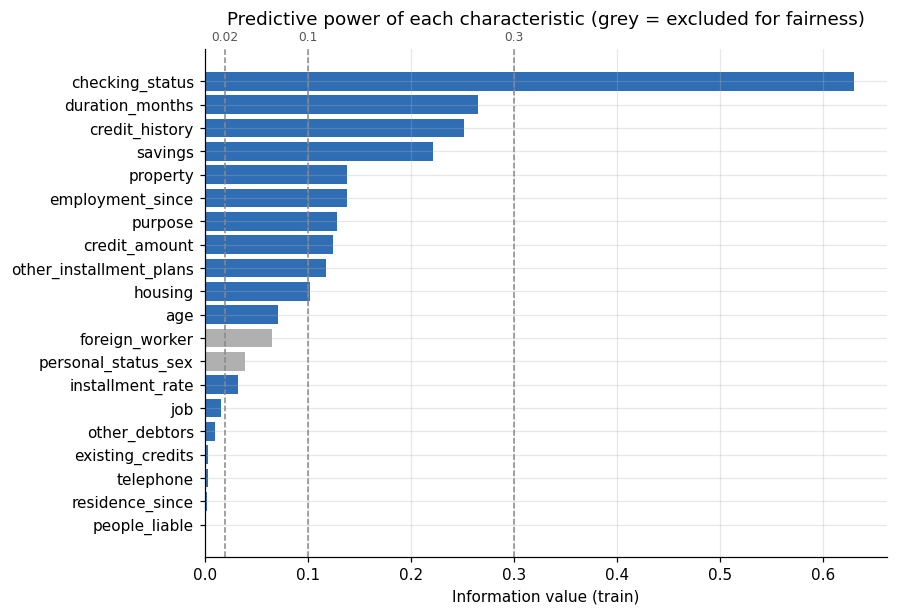

In [8]:
fig, ax = plt.subplots(figsize=(8, 6))
colors = ["#b0b0b0" if c in EXCLUDED else "#2f6db5" for c in binner.iv.index]
ax.barh(binner.iv.index[::-1], binner.iv.values[::-1], color=colors[::-1])
for x0, lab in [(0.02, "0.02"), (0.1, "0.1"), (0.3, "0.3")]:
    ax.axvline(x0, ls="--", lw=1, color="#888")
    ax.text(x0, 1.01, lab, transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=8, color="#555")
ax.set_xlabel("Information value (train)")
ax.set_title("Predictive power of each characteristic (grey = excluded for fairness)", pad=16)
save(fig, "iv.png")
plt.show()

Checking-account status is the strongest characteristic by a wide margin. That is not leakage: the account status is known when the person applies. Applicants without a checking account at the bank are the riskiest group, and those with 200 DM or more or a salary account are the safest.

Below are the bins of a few characteristics. The default rate moves in one direction across the bins of every numeric characteristic, which is what the merge step guarantees.

In [9]:
show_cols = ["share", "n", "bad", "bad_rate", "woe", "iv"]
for col in ["checking_status", "duration_months", "purpose", "credit_amount"]:
    print(f"\n{col}  (IV = {binner.iv[col]:.3f})")
    display(binner.tables[col][show_cols].round(3))


checking_status  (IV = 0.630)


,share,n,bad,bad_rate,woe,iv
bin,,,,,,
>= 200 DM or salary account,0.394,276,32,0.116,1.176,0.404
0 to <200 DM,0.063,44,12,0.273,0.114,0.001
< 0 DM,0.269,188,74,0.394,-0.412,0.049
No checking account,0.274,192,92,0.479,-0.759,0.176



duration_months  (IV = 0.266)


,share,n,bad,bad_rate,woe,iv
bin,,,,,,
<= 8,0.094,66,6,0.091,1.390,0.128
9-16,0.347,243,58,0.239,0.313,0.032
17-34,0.389,272,92,0.338,-0.172,0.012
35-47,0.109,76,31,0.408,-0.473,0.026
>= 48,0.061,43,23,0.535,-0.977,0.067



purpose  (IV = 0.129)


,share,n,bad,bad_rate,woe,iv
bin,,,,,,
Car (new) | Vacation,0.116,81,16,0.198,0.538,0.030
Furniture/equipment,0.266,186,42,0.226,0.383,0.036
Car (used) | Radio/TV,0.194,136,44,0.324,-0.109,0.002
Other | Retraining | Domestic appliances | Business,0.374,262,90,0.344,-0.196,0.015
Repairs,0.050,35,18,0.514,-0.896,0.046



credit_amount  (IV = 0.124)


,share,n,bad,bad_rate,woe,iv
bin,,,,,,
<= 3913,0.741,519,135,0.260,0.200,0.028
3914-7760,0.186,130,48,0.369,-0.312,0.019
>= 7761,0.073,51,27,0.529,-0.959,0.077


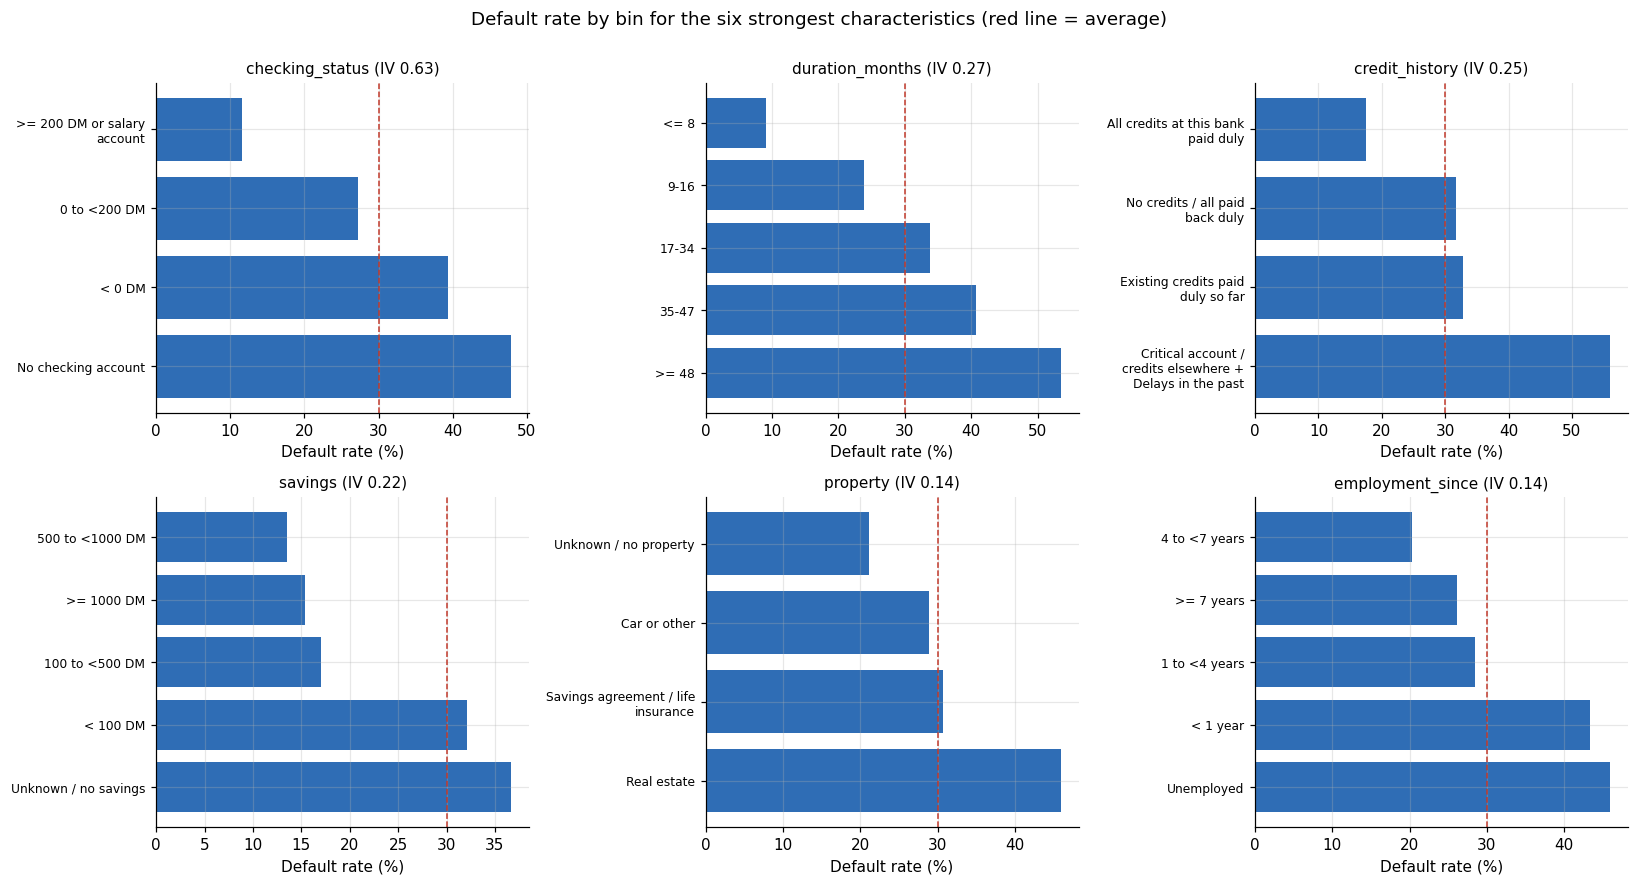

In [10]:
import textwrap

top6 = [c for c in binner.iv.index if c not in EXCLUDED][:6]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), top6):
    t = binner.tables[col]
    labels = [textwrap.fill(str(i).replace(" | ", " + "), 24) for i in t.index]
    ax.barh(labels[::-1], t["bad_rate"].values[::-1] * 100, color="#2f6db5")
    ax.axvline(y_train.mean() * 100, ls="--", lw=1, color="#c0392b")
    ax.set_title(f"{col} (IV {binner.iv[col]:.2f})", fontsize=10)
    ax.set_xlabel("Default rate (%)")
    ax.tick_params(axis="y", labelsize=8)
fig.suptitle("Default rate by bin for the six strongest characteristics (red line = average)", y=1.0)
fig.tight_layout()
save(fig, "bins_top6.png")
plt.show()

With the corrected code table, most characteristics move the way a credit officer would expect: the longer the credit and the weaker the checking account, savings or repayment history, the higher the default rate. A few do not. Home owners default more often than renters, holders of real estate more often than people without property, and borrowers whose installments take less than 20% of their income more often than those above 35%. The likeliest reason is selection: every borrower here was approved, and the bank probably accepted heavier commitments only from applicants who were strong in other ways. The scorecard follows the data, but in a production model I would review such characteristics with the business before giving them points.

## 4. Variable selection and model

The rules, in order:

1. IV of at least 0.02, and not one of the excluded characteristics.
2. WoE correlation below 0.6 with every variable already kept. When two variables are too correlated, the one with the higher IV stays.
3. Backward elimination on the logistic regression: while any coefficient has the wrong sign or a p-value above 0.05, drop the worst one and refit.

WoE is defined as ln(%good/%bad) and the model predicts default, so every coefficient should be negative. A positive one would mean the model contradicts the binning, which usually points to collinearity.

In [11]:
candidates = [c for c in binner.iv.index if binner.iv[c] >= 0.02 and c not in EXCLUDED]
W_train = binner.transform(X_train, candidates)
W_test = binner.transform(X_test, candidates)

corr = W_train.corr().abs()
kept = []
for c in candidates:  # already sorted by IV, highest first
    clash = [k for k in kept if corr.loc[c, k] >= 0.6]
    if clash:
        print(f"drop {c}: WoE correlation {corr.loc[c, clash[0]]:.2f} with {clash[0]}")
    else:
        kept.append(c)
print(f"{len(kept)} candidates after the IV and correlation filters:\n{kept}")

12 candidates after the IV and correlation filters:
['checking_status', 'duration_months', 'credit_history', 'savings', 'property', 'employment_since', 'purpose', 'credit_amount', 'other_installment_plans', 'housing', 'age', 'installment_rate']


In [12]:
def fit_logit(W, y, cols):
    return sm.Logit(y, sm.add_constant(W[cols])).fit(disp=0)

features = kept.copy()
while True:
    model = fit_logit(W_train, y_train, features)
    coef, pval = model.params.drop("const"), model.pvalues.drop("const")
    wrong_sign = coef[coef > 0].index
    if len(wrong_sign):
        worst, reason = pval[wrong_sign].idxmax(), "positive coefficient"
    elif pval.max() > 0.05:
        worst, reason = pval.idxmax(), f"p-value {pval.max():.3f}"
    else:
        break
    print(f"drop {worst}: {reason}")
    features.remove(worst)

print(f"\nFinal model: {len(features)} variables")
summary = model.summary2().tables[1].round(3)
summary["VIF"] = [np.nan] + [round(variance_inflation_factor(sm.add_constant(W_train[features]).values, i), 2)
                             for i in range(1, len(features) + 1)]
summary

drop property: p-value 0.495
drop age: p-value 0.069

Final model: 10 variables


,Coef.,Std.Err.,z,P>|z|,[0.025,0.975],VIF
const,-0.865,0.100,-8.619,0.000,-1.062,-0.668,NaN
checking_status,-0.789,0.131,-6.015,0.000,-1.046,-0.532,1.14
duration_months,-0.834,0.229,-3.639,0.000,-1.284,-0.385,1.37
credit_history,-0.662,0.201,-3.290,0.001,-1.057,-0.268,1.13
savings,-0.927,0.232,-4.002,0.000,-1.382,-0.473,1.08
employment_since,-0.869,0.260,-3.339,0.001,-1.379,-0.359,1.06
purpose,-1.014,0.277,-3.664,0.000,-1.556,-0.471,1.03
credit_amount,-0.702,0.325,-2.160,0.031,-1.338,-0.065,1.38
other_installment_plans,-0.782,0.281,-2.780,0.005,-1.333,-0.231,1.07
housing,-0.650,0.303,-2.142,0.032,-1.244,-0.055,1.04


All coefficients are negative and significant, and the variance inflation factors stay close to 1, so the variables carry separate information.

## 5. Validation

- Discrimination: Gini (2 × AUC − 1) and the Kolmogorov-Smirnov (KS) statistic. For application scorecards, a test Gini above 0.4 and KS above 0.3 are usually considered acceptable.
- Calibration: predicted versus observed default rate by decile, with the Hosmer-Lemeshow test. A p-value above 0.05 means there is no evidence of miscalibration.
- Stability: population stability index (PSI) of the score between train and test. Below 0.1 is stable, 0.1 to 0.25 needs monitoring, above 0.25 means the population has shifted.

In [13]:
def gini(y, p):
    return 2 * roc_auc_score(y, p) - 1


def ks_stat(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    return float(np.max(tpr - fpr))


def hosmer_lemeshow(y, p, groups=10):
    d = pd.DataFrame({"y": np.asarray(y), "p": np.asarray(p)})
    d["decile"] = pd.qcut(d["p"], groups, labels=False, duplicates="drop") + 1
    t = d.groupby("decile").agg(n=("y", "size"), observed=("y", "sum"), expected=("p", "sum"))
    stat = (((t["observed"] - t["expected"]) ** 2) / (t["expected"] * (1 - t["expected"] / t["n"]))).sum()
    return t, stat, 1 - chi2.cdf(stat, len(t) - 2)


def psi(expected, actual, bins=10):
    edges = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    e = np.clip(np.histogram(expected, edges)[0] / len(expected), 1e-6, None)
    a = np.clip(np.histogram(actual, edges)[0] / len(actual), 1e-6, None)
    return float(np.sum((a - e) * np.log(a / e)))


pd_train = model.predict(sm.add_constant(W_train[features]))
pd_test = model.predict(sm.add_constant(W_test[features]))

metrics = pd.DataFrame({
    "AUC": [roc_auc_score(y_train, pd_train), roc_auc_score(y_test, pd_test)],
    "Gini": [gini(y_train, pd_train), gini(y_test, pd_test)],
    "KS": [ks_stat(y_train, pd_train), ks_stat(y_test, pd_test)],
    "mean PD": [pd_train.mean(), pd_test.mean()],
    "default rate": [y_train.mean(), y_test.mean()],
}, index=["train", "test"])
metrics.round(3)

,AUC,Gini,KS,mean PD,default rate
train,0.822,0.644,0.516,0.300,0.3
test,0.792,0.583,0.500,0.299,0.3


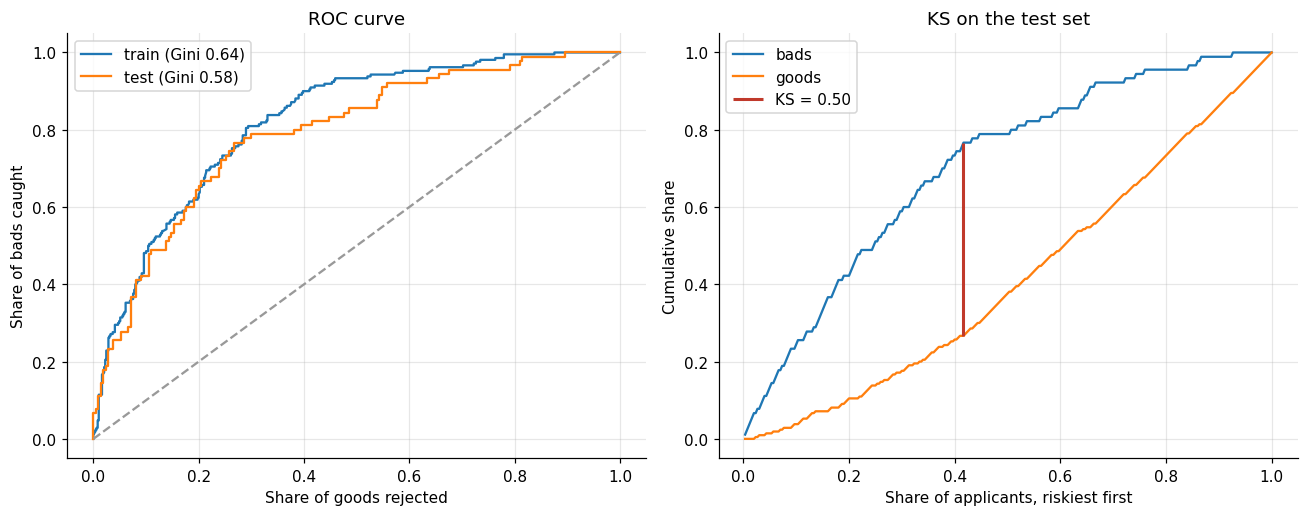

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for name, yy, pp in [("train", y_train, pd_train), ("test", y_test, pd_test)]:
    fpr, tpr, _ = roc_curve(yy, pp)
    axes[0].plot(fpr, tpr, label=f"{name} (Gini {gini(yy, pp):.2f})")
axes[0].plot([0, 1], [0, 1], ls="--", color="#999")
axes[0].set(xlabel="Share of goods rejected", ylabel="Share of bads caught", title="ROC curve")
axes[0].legend()

order = np.argsort(-pd_test.to_numpy())          # riskiest applicants first
yy = y_test.to_numpy()[order]
cum_bad = np.cumsum(yy) / yy.sum()
cum_good = np.cumsum(1 - yy) / (1 - yy).sum()
pop = np.arange(1, len(yy) + 1) / len(yy)
k = int(np.argmax(cum_bad - cum_good))
axes[1].plot(pop, cum_bad, label="bads")
axes[1].plot(pop, cum_good, label="goods")
axes[1].vlines(pop[k], cum_good[k], cum_bad[k], color="#c0392b", lw=2, label=f"KS = {cum_bad[k] - cum_good[k]:.2f}")
axes[1].set(xlabel="Share of applicants, riskiest first", ylabel="Cumulative share", title="KS on the test set")
axes[1].legend()
fig.tight_layout()
save(fig, "roc_ks.png")
plt.show()

Hosmer-Lemeshow (test): statistic 4.40, p-value 0.819


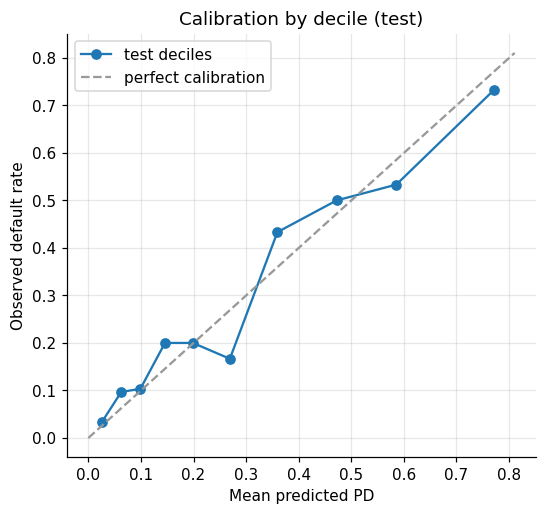

,n,observed,expected,mean_pd,default_rate
decile,,,,,
1,30,1,0.768,0.026,0.033
2,31,3,1.938,0.063,0.097
3,29,3,2.868,0.099,0.103
4,30,6,4.370,0.146,0.200
5,30,6,5.966,0.199,0.200
6,30,5,8.071,0.269,0.167
7,30,13,10.785,0.360,0.433
8,30,15,14.158,0.472,0.500
9,30,16,17.566,0.586,0.533


In [15]:
hl_table, hl_stat, hl_p = hosmer_lemeshow(y_test, pd_test)
hl_table["mean_pd"] = hl_table["expected"] / hl_table["n"]
hl_table["default_rate"] = hl_table["observed"] / hl_table["n"]
print(f"Hosmer-Lemeshow (test): statistic {hl_stat:.2f}, p-value {hl_p:.3f}")

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(hl_table["mean_pd"], hl_table["default_rate"], "o-", label="test deciles")
lim = max(hl_table["mean_pd"].max(), hl_table["default_rate"].max()) * 1.05
ax.plot([0, lim], [0, lim], ls="--", color="#999", label="perfect calibration")
ax.set(xlabel="Mean predicted PD", ylabel="Observed default rate", title="Calibration by decile (test)")
ax.legend()
save(fig, "calibration.png")
plt.show()
hl_table.round(3)

## 6. Scorecard

The model is scaled so that 600 points mean good:bad odds of 50:1 and every 20 points double the odds (PDO = 20):

$$\text{Factor} = \frac{\text{PDO}}{\ln 2}, \qquad \text{Offset} = 600 - \text{Factor} \times \ln 50$$

With $n$ variables, intercept $\alpha$ and coefficients $\beta_j$, bin $k$ of variable $j$ gets

$$\text{Points}_{j,k} = -\left(\beta_j \cdot \text{WoE}_{j,k} + \frac{\alpha}{n}\right) \times \text{Factor} + \frac{\text{Offset}}{n}$$

An applicant's score is the sum of the points of the bins they fall into. A higher score means lower risk.

In [16]:
PDO, BASE_SCORE, BASE_ODDS = 20, 600, 50
FACTOR = PDO / np.log(2)
OFFSET = BASE_SCORE - FACTOR * np.log(BASE_ODDS)

alpha = model.params["const"]
betas = model.params.drop("const")
n_vars = len(betas)

rows = []
for col in betas.index:
    for bin_label, r in binner.tables[col].iterrows():
        points = -(betas[col] * r["woe"] + alpha / n_vars) * FACTOR + OFFSET / n_vars
        rows.append({"variable": col, "bin": str(bin_label), "share_train": r["share"],
                     "default_rate_train": r["bad_rate"], "woe": r["woe"], "points": int(round(points))})
scorecard = pd.DataFrame(rows)
NEUTRAL_POINTS = int(round(-(alpha / n_vars) * FACTOR + OFFSET / n_vars))  # unseen category, WoE = 0
scorecard.to_csv(OUT_DIR / "scorecard.csv", index=False)

lo = scorecard.groupby("variable")["points"].min().sum()
hi = scorecard.groupby("variable")["points"].max().sum()
print(f"Factor = {FACTOR:.2f}, Offset = {OFFSET:.2f}, possible scores from {lo} to {hi}")
scorecard.round(3)

Factor = 28.85, Offset = 487.12, possible scores from 346 to 666


,variable,bin,share_train,default_rate_train,woe,points
0,checking_status,>= 200 DM or salary account,0.394,0.116,1.176,78
1,checking_status,0 to <200 DM,0.063,0.273,0.114,54
2,checking_status,< 0 DM,0.269,0.394,-0.412,42
3,checking_status,No checking account,0.274,0.479,-0.759,34
4,duration_months,<= 8,0.094,0.091,1.390,85
5,duration_months,9-16,0.347,0.239,0.313,59
6,duration_months,17-34,0.389,0.338,-0.172,47
7,duration_months,35-47,0.109,0.408,-0.473,40
8,duration_months,>= 48,0.061,0.535,-0.977,28
9,credit_history,All credits at this bank paid duly,0.293,0.176,0.694,64


Gini of the rounded points score (test): 0.583
PSI of the score, train vs test: 0.031


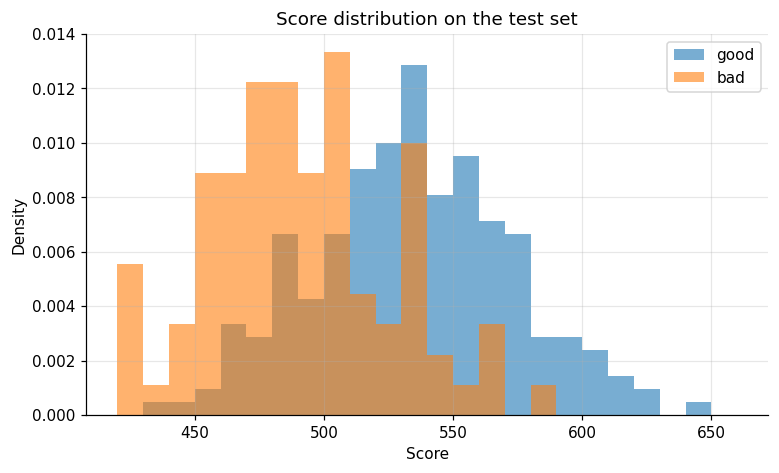

In [17]:
def score_applicants(Xd):
    total = pd.Series(0.0, index=Xd.index)
    for col in betas.index:
        pts = scorecard.loc[scorecard["variable"] == col].set_index("bin")["points"].to_dict()
        bins = pd.Series(np.asarray(binner.assign(Xd[col], col), dtype=object), index=Xd.index)
        total += bins.map(lambda b: pts.get(str(b), NEUTRAL_POINTS))
    return total.astype(int)


def score_to_pd(score):
    return 1 / (1 + np.exp((score - OFFSET) / FACTOR))


score_train, score_test = score_applicants(X_train), score_applicants(X_test)
print(f"Gini of the rounded points score (test): {gini(y_test, -score_test):.3f}")
print(f"PSI of the score, train vs test: {psi(score_train, score_test):.3f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
edges = np.arange(score_test.min() // 10 * 10, score_test.max() + 20, 10)
ax.hist(score_test[y_test == 0], bins=edges, alpha=0.6, density=True, label="good")
ax.hist(score_test[y_test == 1], bins=edges, alpha=0.6, density=True, label="bad")
ax.set(xlabel="Score", ylabel="Density", title="Score distribution on the test set")
ax.legend()
save(fig, "score_distribution.png")
plt.show()

How one test applicant gets scored, characteristic by characteristic:

In [18]:
applicant = X_test.iloc[[0]]
parts = []
for col in betas.index:
    b = str(np.asarray(binner.assign(applicant[col], col), dtype=object)[0])
    pts = scorecard.loc[(scorecard["variable"] == col) & (scorecard["bin"] == b), "points"]
    parts.append({"characteristic": col, "value": applicant[col].iloc[0], "bin": b,
                  "points": int(pts.iloc[0]) if len(pts) else NEUTRAL_POINTS})
parts = pd.DataFrame(parts)
total = int(parts["points"].sum())
print(f"Applicant {applicant.index[0]}: score {total}, PD implied by the score {score_to_pd(total):.1%}, "
      f"actual outcome {'bad' if y_test.iloc[0] == 1 else 'good'}")
parts

Applicant 115: score 570, PD implied by the score 5.4%, actual outcome good


,characteristic,value,bin,points
0,checking_status,>= 200 DM or salary account,>= 200 DM or salary account,78
1,duration_months,48,>= 48,28
2,credit_history,All credits at this bank paid duly,All credits at this bank paid duly,64
3,savings,>= 1000 DM,>= 1000 DM,74
4,employment_since,>= 7 years,>= 7 years,56
5,purpose,Furniture/equipment,Furniture/equipment,62
6,credit_amount,3578,<= 3913,55
7,other_installment_plans,No other plans,No other plans,55
8,housing,Rent,Rent,55
9,installment_rate,< 20%,< 20%,43


## 7. Cut-off strategy

Using the cost matrix, approving an applicant with default probability $p$ costs $5p$ on average and rejecting them costs $1 - p$. Approving is cheaper when $p < 1/6$, that is when the good:bad odds are above 5:1, which on this scale means a score of about $\text{Offset} + \text{Factor} \times \ln 5$.

I search the cut-off on the training set and only check it on the test set, so the threshold is not tuned on the data it is judged on.

In [19]:
COST_BAD_ACCEPTED, COST_GOOD_REJECTED = 5, 1


def cutoff_table(score, y):
    rows = []
    for c in range(int(score.min()), int(score.max()) + 2):
        approve = score >= c
        rows.append({
            "cutoff": c,
            "approval_rate": approve.mean(),
            "bad_rate_approved": y[approve].mean() if approve.any() else np.nan,
            "cost_per_applicant": (COST_BAD_ACCEPTED * (approve & (y == 1)).sum()
                                   + COST_GOOD_REJECTED * (~approve & (y == 0)).sum()) / len(y),
        })
    return pd.DataFrame(rows).set_index("cutoff")


cut_train, cut_test = cutoff_table(score_train, y_train), cutoff_table(score_test, y_test)
best_cutoff = int(cut_train["cost_per_applicant"].idxmin())
theory_cutoff = OFFSET + FACTOR * np.log(COST_BAD_ACCEPTED / COST_GOOD_REJECTED)
at_cut = cut_test.loc[best_cutoff]
approve_all = COST_BAD_ACCEPTED * y_test.mean()
reject_all = COST_GOOD_REJECTED * (1 - y_test.mean())

print(f"Lowest-cost cut-off on train: {best_cutoff} (theory: {theory_cutoff:.1f})")
print(f"Test set at {best_cutoff}: approval rate {at_cut.approval_rate:.1%}, "
      f"default rate among approved {at_cut.bad_rate_approved:.1%} (portfolio {y_test.mean():.1%})")
print(f"Cost per applicant: {at_cut.cost_per_applicant:.2f} with the scorecard, "
      f"{approve_all:.2f} if everyone is approved, {reject_all:.2f} if everyone is rejected")

Lowest-cost cut-off on train: 528 (theory: 533.6)
Test set at 528: approval rate 45.3%, default rate among approved 11.8% (portfolio 30.0%)
Cost per applicant: 0.57 with the scorecard, 1.50 if everyone is approved, 0.70 if everyone is rejected


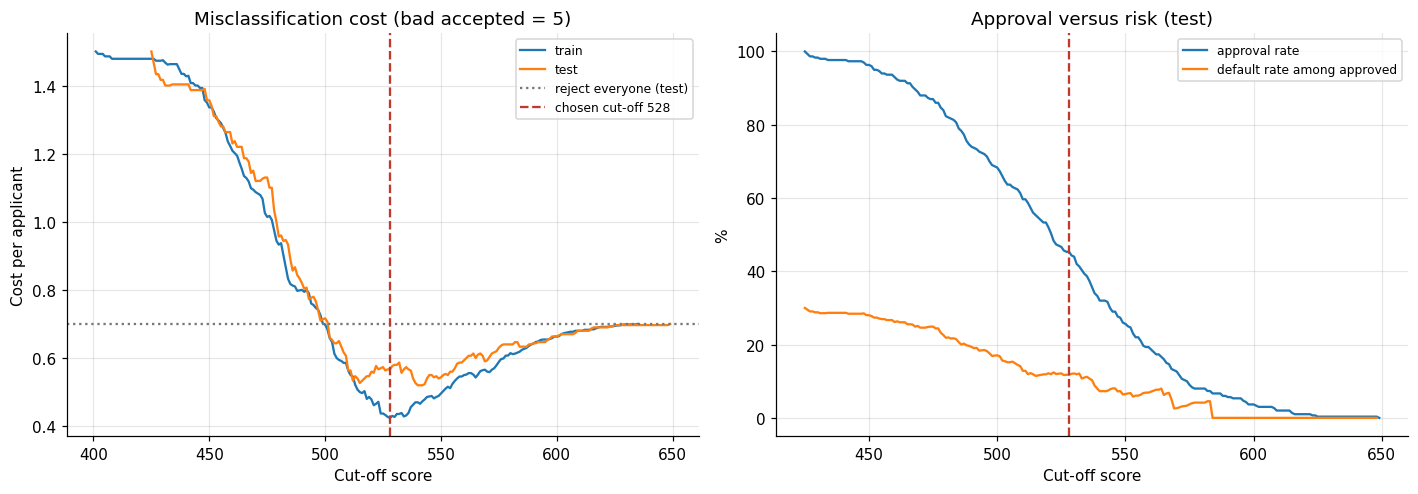

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].plot(cut_train.index, cut_train["cost_per_applicant"], label="train")
axes[0].plot(cut_test.index, cut_test["cost_per_applicant"], label="test")
axes[0].axhline(reject_all, ls=":", color="#777", label="reject everyone (test)")
axes[0].axvline(best_cutoff, ls="--", color="#c0392b", label=f"chosen cut-off {best_cutoff}")
axes[0].set(xlabel="Cut-off score", ylabel="Cost per applicant", title="Misclassification cost (bad accepted = 5)")
axes[0].legend(fontsize=8)

axes[1].plot(cut_test.index, cut_test["approval_rate"] * 100, label="approval rate")
axes[1].plot(cut_test.index, cut_test["bad_rate_approved"] * 100, label="default rate among approved")
axes[1].axvline(best_cutoff, ls="--", color="#c0392b")
axes[1].set(xlabel="Cut-off score", ylabel="%", title="Approval versus risk (test)")
axes[1].legend(fontsize=8)
fig.tight_layout()
save(fig, "cutoff.png")
plt.show()

In [21]:
band_edges = [-np.inf, 460, 480, 500, 520, 540, 560, 580, np.inf]
band_labels = ["< 460", "460-479", "480-499", "500-519", "520-539", "540-559", "560-579", ">= 580"]
band = pd.cut(score_test, band_edges, labels=band_labels, right=False)
strategy = (pd.DataFrame({"band": band, "bad": y_test})
              .groupby("band", observed=False).agg(applicants=("bad", "size"), bads=("bad", "sum")))
strategy["default_rate"] = strategy["bads"] / strategy["applicants"]
from_top = strategy.iloc[::-1]
strategy["approval_rate_if_cutoff_here"] = (from_top["applicants"].cumsum() / from_top["applicants"].sum()).iloc[::-1]
strategy["default_rate_of_approved"] = (from_top["bads"].cumsum() / from_top["applicants"].cumsum()).iloc[::-1]
strategy.round(3)

,applicants,bads,default_rate,approval_rate_if_cutoff_here,default_rate_of_approved
band,,,,,
< 460,21,17,0.810,1.000,0.300
460-479,32,19,0.594,0.930,0.262
480-499,42,19,0.452,0.823,0.219
500-519,49,16,0.327,0.683,0.171
520-539,60,12,0.200,0.520,0.122
540-559,40,3,0.075,0.320,0.073
560-579,32,3,0.094,0.187,0.071
>= 580,24,1,0.042,0.080,0.042


The score bands make the trade-off concrete for a credit committee: each step down in the cut-off approves more people, and the table shows how much risk comes with them.

## 8. Expected credit loss (IFRS 9 / PSAK 109)

ECL is the probability-weighted, discounted credit loss:

$$\text{ECL} = \sum_{s} w_s \sum_{t=1}^{T} \text{PD}_{t,s} \times \text{LGD} \times \text{EAD}_t \times (1 + r)^{-t}$$

- Stage 1 (no significant increase in credit risk): losses from defaults in the next 12 months.
- Stage 2 (significant increase in credit risk, SICR): losses over the remaining life of the loan.
- Stage 3 (credit-impaired): lifetime loss with PD = 1. The portfolio here has no defaulted loans at the reporting date, so Stage 3 is empty.

The German Credit data has no balances, payment history or origination snapshots, so this part runs on stated assumptions. They all sit in one config cell, so each can be changed and rerun:

| Item | Assumption |
|---|---|
| Portfolio | All 1,000 loans, scored with the model above |
| Reporting date | Halfway through each loan's term |
| Exposure (EAD) | Annuity loan of `credit_amount` over `duration_months`, effective interest rate 10% p.a.; EAD is the outstanding balance each month. The amounts are transformed (section 2), so DM totals are illustrative and the coverage ratios are the meaningful output |
| PD level | Model PDs shifted on the log-odds scale to a 5% average 12-month PD, the share of bad credits the original sources report for the bank's actual book (the 30% in the sample comes from oversampling) |
| PD term structure | Constant monthly hazard implied by the 12-month PD |
| SICR (Stage 2) | 12-month PD at least twice the portfolio average. This is a proxy: real SICR compares current PD with PD at origination, which the data does not have |
| LGD | 45% for every loan |
| Scenarios | Upside 20% (PD × 0.8), base 60% (PD × 1.0), downside 20% (PD × 1.4) |

In [22]:
ECL_CONFIG = {
    "central_tendency_pd": 0.05,  # average 12-month PD after calibration; None keeps the raw model PDs
    "sicr_multiple": 2.0,         # Stage 2 if 12-month PD >= sicr_multiple x portfolio average
    "lgd": 0.45,
    "eir_annual": 0.10,
    "elapsed_share": 0.5,         # share of the term already elapsed at the reporting date
    "scenarios": {"Upside": (0.20, 0.8), "Base": (0.60, 1.0), "Downside": (0.20, 1.4)},  # weight, PD multiplier
}

W_all = binner.transform(X, features)
pd_model = pd.Series(model.predict(sm.add_constant(W_all[features])), index=X.index)


def calibrate_mean(pd_raw, target):
    """Shift the log-odds so the average PD equals target (calibration-in-the-large)."""
    z = logit(np.clip(pd_raw, 1e-6, 1 - 1e-6))
    shift = brentq(lambda d: expit(z + d).mean() - target, -20, 20)
    return pd.Series(expit(z + shift), index=pd_raw.index), shift


def balance_path(principal, term, elapsed, r):
    """Outstanding balance of an annuity loan at the start of each remaining month."""
    payment = principal * r / (1 - (1 + r) ** -term)
    k = np.arange(elapsed, term)
    return principal * (1 + r) ** k - payment * ((1 + r) ** k - 1) / r


def discounted_loss(pd12, balances, horizon, lgd, r):
    """Sum over months of marginal PD x LGD x EAD x discount factor, constant monthly hazard."""
    hazard = 1 - (1 - pd12) ** (1 / 12)
    months = np.arange(1, horizon + 1)
    marginal_pd = (1 - hazard) ** (months - 1) * hazard
    return float(np.sum(marginal_pd * lgd * balances[:horizon] / (1 + r) ** months))


def run_ecl(pd_model, loans, cfg):
    r = cfg["eir_annual"] / 12
    if cfg["central_tendency_pd"] is None:
        pd12, shift = pd_model.copy(), 0.0
    else:
        pd12, shift = calibrate_mean(pd_model, cfg["central_tendency_pd"])
    threshold = cfg["sicr_multiple"] * pd12.mean()
    rows = []
    for i in loans.index:
        term = int(loans.at[i, "duration_months"])
        elapsed = int(np.floor(term * cfg["elapsed_share"]))
        balances = balance_path(float(loans.at[i, "credit_amount"]), term, elapsed, r)
        remaining = term - elapsed
        stage = 2 if pd12[i] >= threshold else 1
        horizon = remaining if stage == 2 else min(12, remaining)
        row = {"loan_id": i, "pd_12m": pd12[i], "stage": stage, "ead": balances[0], "remaining_months": remaining}
        for name, (_, mult) in cfg["scenarios"].items():
            p = min(pd12[i] * mult, 0.999)
            row[f"ecl_{name.lower()}"] = discounted_loss(p, balances, horizon, cfg["lgd"], r)
            row[f"ecl12_{name.lower()}"] = discounted_loss(p, balances, min(12, remaining), cfg["lgd"], r)
        rows.append(row)
    out = pd.DataFrame(rows).set_index("loan_id")
    weights = {name.lower(): w for name, (w, _) in cfg["scenarios"].items()}
    out["ecl"] = sum(w * out[f"ecl_{n}"] for n, w in weights.items())
    out["ecl_if_all_stage1"] = sum(w * out[f"ecl12_{n}"] for n, w in weights.items())
    return out, shift, threshold


loans, shift, sicr_threshold = run_ecl(pd_model, X, ECL_CONFIG)
loans.insert(0, "score", score_applicants(X))
loans.to_csv(OUT_DIR / "ecl_loan_level.csv")
print(f"Log-odds shift {shift:.2f}, average 12-month PD {loans['pd_12m'].mean():.2%}, "
      f"SICR threshold {sicr_threshold:.1%}")

Log-odds shift -2.60, average 12-month PD 5.00%, SICR threshold 10.0%


In [23]:
by_stage = loans.groupby("stage").agg(loans=("ead", "size"), ead=("ead", "sum"),
                                      avg_pd_12m=("pd_12m", "mean"), ecl=("ecl", "sum"))
by_stage.index = [f"Stage {s}" for s in by_stage.index]
by_stage.loc["Total"] = [len(loans), loans["ead"].sum(), loans["pd_12m"].mean(), loans["ecl"].sum()]
by_stage["share_of_ead"] = by_stage["ead"] / loans["ead"].sum()
by_stage["share_of_ecl"] = by_stage["ecl"] / loans["ecl"].sum()
by_stage["coverage"] = by_stage["ecl"] / by_stage["ead"]
by_stage.to_csv(OUT_DIR / "ecl_by_stage.csv")

uplift = loans["ecl"].sum() / loans["ecl_if_all_stage1"].sum() - 1
print(f"Lifetime ECL on Stage 2 adds {uplift:.0%} compared with a 12-month allowance on every loan.")
by_stage.style.format({"loans": "{:,.0f}", "ead": "{:,.0f}", "avg_pd_12m": "{:.2%}", "ecl": "{:,.0f}",
                       "share_of_ead": "{:.1%}", "share_of_ecl": "{:.1%}", "coverage": "{:.2%}"})

Lifetime ECL on Stage 2 adds 13% compared with a 12-month allowance on every loan.


,loans,ead,avg_pd_12m,ecl,share_of_ead,share_of_ecl,coverage
Stage 1,854,"1,351,225",2.60%,"9,946",77.4%,23.2%,0.74%
Stage 2,146,"393,480",19.01%,"33,017",22.6%,76.8%,8.39%
Total,"1,000","1,744,705",5.00%,"42,963",100.0%,100.0%,2.46%


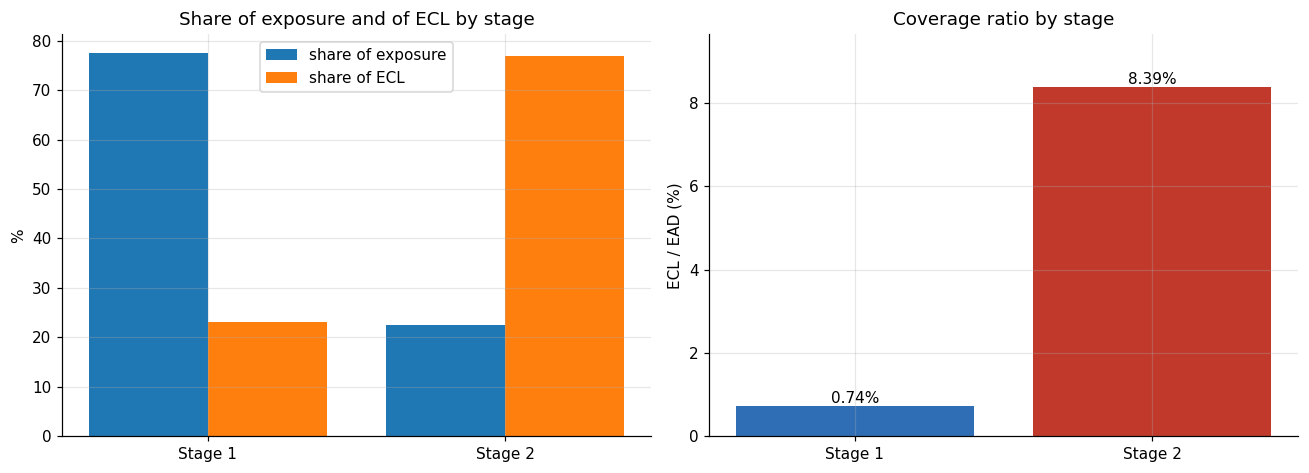

In [24]:
stages = by_stage.drop(index="Total")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
x = np.arange(len(stages))
axes[0].bar(x - 0.2, stages["share_of_ead"] * 100, width=0.4, label="share of exposure")
axes[0].bar(x + 0.2, stages["share_of_ecl"] * 100, width=0.4, label="share of ECL")
axes[0].set_xticks(x, stages.index)
axes[0].set(ylabel="%", title="Share of exposure and of ECL by stage")
axes[0].legend()
axes[1].bar(stages.index, stages["coverage"] * 100, color=["#2f6db5", "#c0392b"][:len(stages)])
for i, v in enumerate(stages["coverage"] * 100):
    axes[1].text(i, v, f"{v:.2f}%", ha="center", va="bottom")
axes[1].set_ylim(0, stages["coverage"].max() * 100 * 1.15)
axes[1].set(ylabel="ECL / EAD (%)", title="Coverage ratio by stage")
fig.tight_layout()
save(fig, "ecl_by_stage.png")
plt.show()

In [25]:
scenario_table = pd.DataFrame(
    [{"scenario": name, "weight": w, "PD multiplier": m, "ECL (DM)": loans[f"ecl_{name.lower()}"].sum()}
     for name, (w, m) in ECL_CONFIG["scenarios"].items()]
    + [{"scenario": "Probability-weighted", "weight": 1.0, "PD multiplier": np.nan, "ECL (DM)": loans["ecl"].sum()}]
).set_index("scenario")
scenario_table.style.format({"weight": "{:.0%}", "PD multiplier": "{:.1f}", "ECL (DM)": "{:,.0f}"}, na_rep="")

,weight,PD multiplier,ECL (DM)
scenario,,,
Upside,20%,0.8,"33,359"
Base,60%,1.0,"41,406"
Downside,20%,1.4,"57,237"
Probability-weighted,100%,,"42,963"


Sensitivity of total coverage (ECL / EAD) to the two assumptions with the most judgement in them: the average PD level and the SICR rule. LGD is left out of the grid because ECL scales one-for-one with it.

In [26]:
grid = {}
for ct in [0.03, 0.05, 0.08]:
    for mult in [1.5, 2.0, 3.0]:
        res, _, _ = run_ecl(pd_model, X, {**ECL_CONFIG, "central_tendency_pd": ct, "sicr_multiple": mult})
        grid[(f"{ct:.0%}", f"{mult:g}x")] = res["ecl"].sum() / res["ead"].sum()
sensitivity = pd.Series(grid).unstack()
sensitivity.index.name, sensitivity.columns.name = "average 12m PD", "SICR multiple"
print(f"Loans with more than 12 months left at the reporting date: {(loans['remaining_months'] > 12).mean():.0%}")
sensitivity.style.format("{:.2%}")

Loans with more than 12 months left at the reporting date: 23%


SICR multiple,1.5x,2x,3x
average 12m PD,,,
3%,1.57%,1.57%,1.55%
5%,2.48%,2.46%,2.44%
8%,3.73%,3.70%,3.66%


The average PD level moves coverage far more than the SICR rule. The reason sits in the exposure assumption: with half of each term already gone, most loans have 12 months or less left, so their lifetime and 12-month ECL are almost the same. Staging only changes the number for the longer loans, which is also why the lifetime uplift above is modest.

## 9. Summary

In [27]:
summary = pd.Series({
    "Characteristics in the scorecard": len(features),
    "Test Gini": f"{gini(y_test, pd_test):.3f}",
    "Test KS": f"{ks_stat(y_test, pd_test):.3f}",
    "Hosmer-Lemeshow p-value (test)": f"{hl_p:.3f}",
    "Score PSI, train vs test": f"{psi(score_train, score_test):.3f}",
    "Cut-off (lowest cost on train)": best_cutoff,
    "Approval rate at cut-off (test)": f"{at_cut.approval_rate:.1%}",
    "Default rate among approved (test)": f"{at_cut.bad_rate_approved:.1%}",
    "Total EAD (DM)": f"{loans['ead'].sum():,.0f}",
    "Total ECL (DM)": f"{loans['ecl'].sum():,.0f}",
    "Coverage (ECL / EAD)": f"{loans['ecl'].sum() / loans['ead'].sum():.2%}",
    "Stage 2 share of EAD / ECL": f"{by_stage.loc['Stage 2', 'share_of_ead']:.1%} / {by_stage.loc['Stage 2', 'share_of_ecl']:.1%}",
}, name="value")
summary.to_frame()

,value
Characteristics in the scorecard,10
Test Gini,0.583
Test KS,0.500
Hosmer-Lemeshow p-value (test),0.819
"Score PSI, train vs test",0.031
Cut-off (lowest cost on train),528
Approval rate at cut-off (test),45.3%
Default rate among approved (test),11.8%
Total EAD (DM),"1,744,705"
Total ECL (DM),"42,963"


## 10. Limitations and next steps

- 1,000 credits from 1973 to 1975 and one random split. An out-of-time sample would be the real test, and a 1970s German bank is a long way from a current Indonesian loan book.
- Outcomes exist only for approved borrowers, so the model inherits the selection made by the old credit policy, which probably explains the odd directions for housing, property and installment rate. Reject inference is the usual way to deal with this.
- In the ECL part, the 5% PD level comes from the original sources, but LGD, the SICR rule, the scenario weights and the amortization profile are assumptions, and the credit amounts are transformed. With real data I would build the PD term structure from vintage or roll-rate data, estimate LGD from recoveries, link the scenario multipliers to a macro model (GDP growth, unemployment, policy rate), and compare current PD with PD at origination for SICR.
- The binning routine is deliberately simple. Libraries such as `optbinning` solve the same problem with an optimizer and more constraints.

## References

- Hofmann, H. (1994). Statlog (German Credit Data) [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5NC77
- Grömping, U. (2019). *South German Credit Data: Correcting a Widely Used Data Set*. Report 4/2019, Reports in Mathematics, Physics and Chemistry, Department II, Beuth University of Applied Sciences Berlin. The corrected data is on UCI as South German Credit, https://doi.org/10.24432/C5X89F
- Siddiqi, N. (2017). *Intelligent Credit Scoring: Building and Implementing Better Credit Risk Scorecards* (2nd ed.). Wiley.
- IFRS Foundation. *IFRS 9 Financial Instruments*.
- Ikatan Akuntan Indonesia. *PSAK 109 Instrumen Keuangan* (formerly PSAK 71).